<a href="https://colab.research.google.com/github/Isabella-de-Lima/python_sis_26_2/blob/isabella_lima_2_bimestre/aula_13/isabella_lima_aula13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# AULA 13 | ATIVIDADE 01 | Importação de Dados e Tratamento

# Nesta atividade, você atuará como um Analista de Dados preparando a geração de insights.
# Sua missão é estruturar uma base de dados bruta:

# Requisitos:
# *Crie scripts em Python que executem as etapas a seguir:

# Etapa 1:
# importe a biblioteca pandas e outras que necessitar e carregue uma base de dados reais de sua escolha.

import pandas as pd

filmes = pd.read_csv("imdb_top_250_movies.csv") # abre o arquivo e guarda os dados

print(f"🎬 Filmes na base original: {len(filmes)}") # conta as linhas da tabela

# Etapa 2:
# Inspecione a base (use pelo menos head() e info()) e execute um tratamento de dados inconsistentes e
# preencha ou remova valores ausentes (NaN).

display(filmes.head()) # head() pega as cinco primeiras linhas / O display() mostra essas linhas como tabela
filmes.info() # mostra os nomes das colunas, o tipo de dado de cada uma e quantos valores estão preenchidos

colunas = ["id", "primaryTitle", "startYear", "averageRating", "genres"]
filmes_limpos = filmes[colunas].copy() # tabela separada para tratar os dados sem alterar filmes.

for coluna in ["primaryTitle", "genres"]: # limpeza nas colunas de título e gêneros
    filmes_limpos[coluna] = filmes_limpos[coluna].str.strip().replace("", pd.NA)

for coluna in ["startYear", "averageRating"]:
    filmes_limpos[coluna] = pd.to_numeric(
        filmes_limpos[coluna], errors="coerce"
    )

filmes_limpos = filmes_limpos.dropna() # remove linhas com algum valor ausente
filmes_limpos = filmes_limpos[
    filmes_limpos["averageRating"].between(0, 10)
]
filmes_limpos = filmes_limpos.drop_duplicates(subset="id")

print(f"\n✅ Filmes após o tratamento: {len(filmes_limpos)}")

# Etapa 3:
# Escolha uma categoria de interesse, crie um filtro (ex: apenas itens com valor acima de X, ou apenas do ano Y) e
# salve este novo DataFrame limpo em um novo arquivo .csv.

filtro_terror = filmes_limpos["genres"].str.contains(
    r"\bHorror\b", case=False, na=False
)

filmes_terror = filmes_limpos[filtro_terror].sort_values(
    "averageRating", ascending=False
)

nome_arquivo = "filmes_terror_imdb.csv"
filmes_terror.to_csv(nome_arquivo, index=False)

print(f"\n👻 Filmes de terror encontrados: {len(filmes_terror)}")
display(filmes_terror[["primaryTitle", "startYear", "averageRating"]])
print(f"\n✅ Arquivo salvo: {nome_arquivo}")

🎬 Filmes na base original: 250


,id,url,primaryTitle,originalTitle,type,parentImdbId,description,primaryImage,thumbnails,trailer,...,filmingLocations,productionCompanies,budget,grossWorldwide,genres,isAdult,runtimeMinutes,averageRating,numVotes,metascore
0,tt0111161,https://www.imdb.com/title/tt0111161/,The Shawshank Redemption,The Shawshank Redemption,movie,NaN,After a banker is sentenced to life in Shawsha...,https://m.media-amazon.com/images/M/MV5BMDAyY2...,[{'url': 'https://m.media-amazon.com/images/M/...,https://www.youtube.com/watch?v=xyXX8LXiNJ4,...,"['Butler, Ohio, USA']","[{'id': 'co0040620', 'name': 'Castle Rock Ente...",25000000.0,2.942559e+07,['Drama'],False,142,9.3,3254168,82.0
1,tt0068646,https://www.imdb.com/title/tt0068646/,The Godfather,The Godfather,movie,NaN,The aging patriarch of an organized crime dyna...,https://m.media-amazon.com/images/M/MV5BNGEwYj...,[{'url': 'https://m.media-amazon.com/images/M/...,https://www.youtube.com/watch?v=8V2k2YQEQJ4,...,"[""Forza d'Agrò, Messina, Sicily, Italy""]","[{'id': 'co0023400', 'name': 'Paramount Pictur...",6000000.0,2.509356e+08,"['Crime', 'Drama']",False,175,9.2,2265838,100.0
2,tt0468569,https://www.imdb.com/title/tt0468569/,The Dark Knight,The Dark Knight,movie,NaN,When a menace known as the Joker wreaks havoc ...,https://m.media-amazon.com/images/M/MV5BMTMxNT...,[{'url': 'https://m.media-amazon.com/images/M/...,https://www.youtube.com/watch?v=kmJLuwP3MbY,...,"['Chicago, Illinois, USA']","[{'id': 'co0002663', 'name': 'Warner Bros.'}, ...",185000000.0,1.008481e+09,"['Crime', 'Thriller']",False,152,9.1,3240614,85.0
3,tt0071562,https://www.imdb.com/title/tt0071562/,The Godfather Part II,The Godfather Part II,movie,NaN,The early life and career of Vito Corleone in ...,https://m.media-amazon.com/images/M/MV5BMDIxMz...,[{'url': 'https://m.media-amazon.com/images/M/...,https://www.youtube.com/watch?v=9O1Iy9od7-A,...,"['Kaiser Estate - 4000 W Lake Blvd, Homewood, ...","[{'id': 'co0023400', 'name': 'Paramount Pictur...",13000000.0,4.821170e+07,"['Crime', 'Drama']",False,202,9.0,1519575,90.0
4,tt0167260,https://www.imdb.com/title/tt0167260/,The Lord of the Rings: The Return of the King,The Lord of the Rings: The Return of the King,movie,NaN,Gandalf and Aragorn lead the World of Men agai...,https://m.media-amazon.com/images/M/MV5BMTZkMj...,[{'url': 'https://m.media-amazon.com/images/M/...,https://www.youtube.com/watch?v=zckJCxYxn1g,...,"['Hinuera Valley, Matamata, Waikato, New Zeala...","[{'id': 'co0046718', 'name': 'New Line Cinema'...",94000000.0,1.138064e+09,"['Adventure', 'Drama', 'Fantasy']",False,201,9.0,2201719,94.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   250 non-null    object 
 1   url                  250 non-null    object 
 2   primaryTitle         250 non-null    object 
 3   originalTitle        250 non-null    object 
 4   type                 250 non-null    object 
 5   parentImdbId         0 non-null      float64
 6   description          250 non-null    object 
 7   primaryImage         250 non-null    object 
 8   thumbnails           250 non-null    object 
 9   trailer              244 non-null    object 
 10  contentRating        244 non-null    object 
 11  startYear            250 non-null    int64  
 12  endYear              0 non-null      float64
 13  releaseDate          250 non-null    object 
 14  interests            250 non-null    object 
 15  countriesOfOrigin    250 non-null    obj

,primaryTitle,startYear,averageRating
21,The Silence of the Lambs,1991,8.6
38,Psycho,1960,8.5
50,Alien,1979,8.4
68,The Shining,1980,8.4
149,The Thing,1982,8.2
204,Jaws,1975,8.1
235,The Exorcist,1973,8.1



✅ Arquivo salvo: filmes_terror_imdb.csv


👻 Filmes de terror na base: 7

❓ Qual é o filme de terror mais bem avaliado da base?
🏆 The Silence of the Lambs — nota 8,6



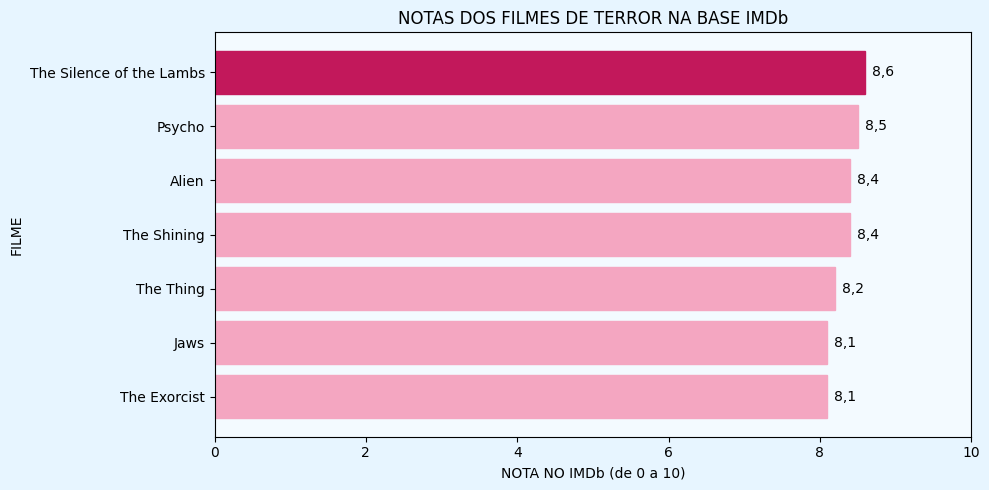

In [ ]:
# AULA 13 | ATIVIDADE 02 | Gráficos de base de dados

# Agora que seus dados estão estruturados, é hora de contar histórias com eles.
# Baseando-se no que vimos sobre boas práticas de visualização.

# Requisitos:
# *Crie scripts em Python que executem as etapas a seguir:

# Etapa 1:
# Importe sua base de dados limpa utilizando o pandas.

import matplotlib.pyplot as plt
import pandas as pd

filmes_terror = pd.read_csv("filmes_terror_imdb.csv")

print(f"👻 Filmes de terror na base: {len(filmes_terror)}")

# Etapa 2:
# Pense em uma pergunta que seus dados podem responder, escolha os tipos de gráficos adequados e
# crie o gráfico.

filmes_terror = filmes_terror.sort_values("averageRating", ascending=False) # ordena a tabela pela coluna que guarda a nota / coloca as notas da maior para a menor

figura, eixo = plt.subplots(figsize=(10, 5))

barras = eixo.barh( # cria um gráfico de barras horizontais
    filmes_terror["primaryTitle"], # nome
    filmes_terror["averageRating"], # nota
)

eixo.invert_yaxis()

# Etapa 3:
# Profissionalize sua visualização: adicione um título, rótulos para os eixos X e Y,
# e ajuste as cores para facilitar o entendimento.

for barra in barras:
    barra.set_color("#F4A6C1")

barras[0].set_color("#C2185B")

figura.patch.set_facecolor("#E7F5FF")
eixo.set_facecolor("#F3FAFF")

eixo.set_title("NOTAS DOS FILMES DE TERROR NA BASE IMDb")
eixo.set_xlabel("NOTA NO IMDb (de 0 a 10)")
eixo.set_ylabel("FILME")
eixo.set_xlim(0, 10)

notas = [
    f"{nota:.1f}".replace(".", ",")
    for nota in filmes_terror["averageRating"]
]
eixo.bar_label(barras, labels=notas, padding=5)

figura.tight_layout()

melhor_filme = filmes_terror.iloc[0]
nota = f"{melhor_filme['averageRating']:.1f}".replace(".", ",")

print("\n❓ Qual é o filme de terror mais bem avaliado da base?")
print(f"🏆 {melhor_filme['primaryTitle']} — nota {nota}\n")

plt.show()